## **Проектная работа №1: Классификация объектов на изображении**









### **Цель:**


Разработать программу на Python, которая принимает на вход фотографию с изображением монет и вычисляет общую сумму денежных средств, отображенных на ней, используя только библиотеку OpenCV и стандартные библиотеки Python.


### **Базовая реализация:**



1. **Сбор изображения:**
   - Используйте камеру или загрузите готовое изображение с монетами для обработки.

2. **Предварительная обработка изображения:**
   - Преобразуйте изображение в оттенки серого.
   - Примените размытие Гаусса для уменьшения шума.
   - Используйте оператор Кэнни для обнаружения краев.

3. **Обнаружение кругов (монет):**
   - Используйте преобразование Хафа для обнаружения кругов на изображении.
   - Получите координаты центров и радиусов обнаруженных кругов (монет).

4. **Классификация монет:**
   - Определите номинал каждой монеты на основе ее радиуса.
   - Установите пороговые значения для радиусов, соответствующие разным номиналам:
     - **Маленький радиус:** 1 рубль.
     - **Средний радиус:** 2 рубля.
     - **Большой радиус:** 5 рублей.

5. **Подсчет общей суммы:**
   - Суммируйте номиналы всех обнаруженных монет.
   - Отобразите общую сумму на изображении или в консоли.

6. **Отображение результатов:**
   - Нарисуйте окружности на изображении вокруг обнаруженных монет.
   - Подпишите рядом с каждой монетой ее номинал.
   - Покажите исходное изображение с отмеченными монетами.
   - Выведите обработанные этапы для визуализации процесса (например, изображение после предварительной обработки, с контурами и т.д.).



### **Требования к реализации:**



- Использовать только библиотеку **OpenCV** и стандартные библиотеки Python (например, **NumPy**).
- Код должен быть хорошо документирован с комментариями для каждого основного блока.
- Предусмотреть возможность настройки параметров обработки через трекбары или отдельные переменные.



### **Рекомендации:**




- **Преобразование Хафа** для кругов является удобным инструментом для обнаружения круглых объектов на изображении.
- **Пороговые значения радиусов** необходимо подобрать экспериментально, протестировав на образцах монет разных номиналов.
- **Обработка перекрывающихся монет** может потребовать более сложных алгоритмов, таких как водоразделение или использование градиентных признаков.
- Тестируйте программу на различных изображениях с разным количеством и расположением монет, а также при разном освещении.





### **Ожидаемый результат:**




В результате выполнения задания вы получите программу, которая способна:

- Принимать на вход изображение с монетами.
- Обрабатывать изображение и обнаруживать монеты без использования библиотеки cvzone.
- Определять номинал каждой монеты на основе ее радиуса или других признаков.
- Вычислять и отображать общую сумму монет на изображении.



---

**Пример использования программы:**

- Пользователь запускает программу.
- Загружается изображение с монетами.
- Программа обрабатывает изображение, отмечает каждую монету и подписывает ее номинал.
- Отображается изображение с результатами и выводится общая сумма, например: **"Общая сумма: 37 рублей"**.



---

**Заметка:**

Данный проект позволит вам:

- Изучить и применить технологии обработки изображений с помощью OpenCV без привлечения сторонних библиотек.
- Научиться решать практические задачи компьютерного зрения, применяя базовые методы и улучшая их по мере необходимости.




---

**Советы по реализации:**

- **Настройка параметров:**
  - Для преобразования Хафа используйте функцию `cv2.HoughCircles()`.
  - Экспериментируйте с параметрами `dp`, `minDist`, `param1`, `param2`, `minRadius`, `maxRadius`.
- **Отображение результатов:**
  - Используйте функцию `cv2.circle()` для рисования окружностей.
  - Для отображения текста воспользуйтесь `cv2.putText()`.
- **Обработка ошибок:**
  - Обрабатывайте случаи, когда преобразование Хафа не обнаруживает ни одной монеты.
  - Предусмотрите проверку входных данных и вывод информативных сообщений для пользователя.

---

# **Решение**

**Используемые изображения:** четыре фотографии `coins_1.jpg` – `coins_4.jpg` (лежат рядом с ноутбуком). На всех снимках один и тот же набор монет, разложенный по-разному и снятый с разной высоты и при разном освещении:

| Номинал | Количество |
|---|---|
| 1 рубль | 16 |
| 2 рубля | 6 |
| 5 рублей | 2 |
| 10 рублей | 4 |
| Посторонняя монета (тёмная, 1955 г.) | 1 — не учитывается |

**Правильная сумма: 78 рублей** (из них 38 рублей — монетами 1, 2 и 5 рублей).

Помимо базовых требований программа: распознаёт монеты 10 рублей и посторонние монеты по цвету; автоматически определяет масштаб снимка (пикселей на миллиметр), чтобы пороги по радиусу работали при любой высоте съёмки.

### **1. Импорты и параметры обработки**

Все параметры собраны в словаре `PARAMS`. Для интерактивного подбора есть функция с трекбарами OpenCV (раздел 7).

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt   # только для вывода изображений в ноутбуке

PARAMS = {
    # --- Предобработка
    "work_width": 1200,      # снимок приводится к этой ширине, чтобы параметры не зависели от разрешения камеры
    "blur_ksize": 9,         # размер ядра размытия Гаусса (нечётный)
    "canny_low": 50,         # нижний порог Кэнни
    "canny_high": 100,       # верхний порог Кэнни (он же param1 у HoughCircles)
    # --- Преобразование Хафа для кругов
    "dp": 1.2,               # отношение разрешения аккумулятора к разрешению изображения
    "min_dist": 60,          # минимальное расстояние между центрами монет, px
    "param2": 40,            # порог аккумулятора: меньше -> больше кругов (в т.ч. ложных)
    "min_radius": 30,        # px при ширине work_width
    "max_radius": 80,
    # --- Классификация по размеру
    "auto_scale": True,      # True: масштаб px/мм определяется автоматически, пороги задаются в мм
    "d_1_2_mm": 21.75,       # граница между 1 руб. (20.5 мм) и 2 руб. (23 мм)
    "d_2_5_mm": 24.0,        # граница между 2 руб. (23 мм) и 5 руб. (25 мм)
    "r_1_2": 51.5,           # пороги радиуса в px — используются при auto_scale = False
    "r_2_5": 56.5,           #   (подобраны по снимку coins_2.jpg, см. раздел 8)
    # --- Классификация по цвету
    "use_color": True,
    "yellow_min_s": 75,      # насыщенность (после баланса белого), начиная с которой монета «жёлтая» -> 10 руб.
    "yellow_h": (13, 25),    # диапазон тона H жёлтой латуни (OpenCV: 0..179)
    "dark_max_v": 0.32,      # яркость бликов монеты относительно фона, ниже которой монета «тёмная» -> посторонняя
}

# Диаметры монет Банка России, мм
COIN_DIAMETERS_MM = {1: 20.5, 2: 23.0, 5: 25.0, 10: 22.0}

### **2. Сбор изображения**

Изображение загружается из файла (поддерживаются пути с кириллицей) или снимается камерой (`cv2.VideoCapture`, при локальном запуске).

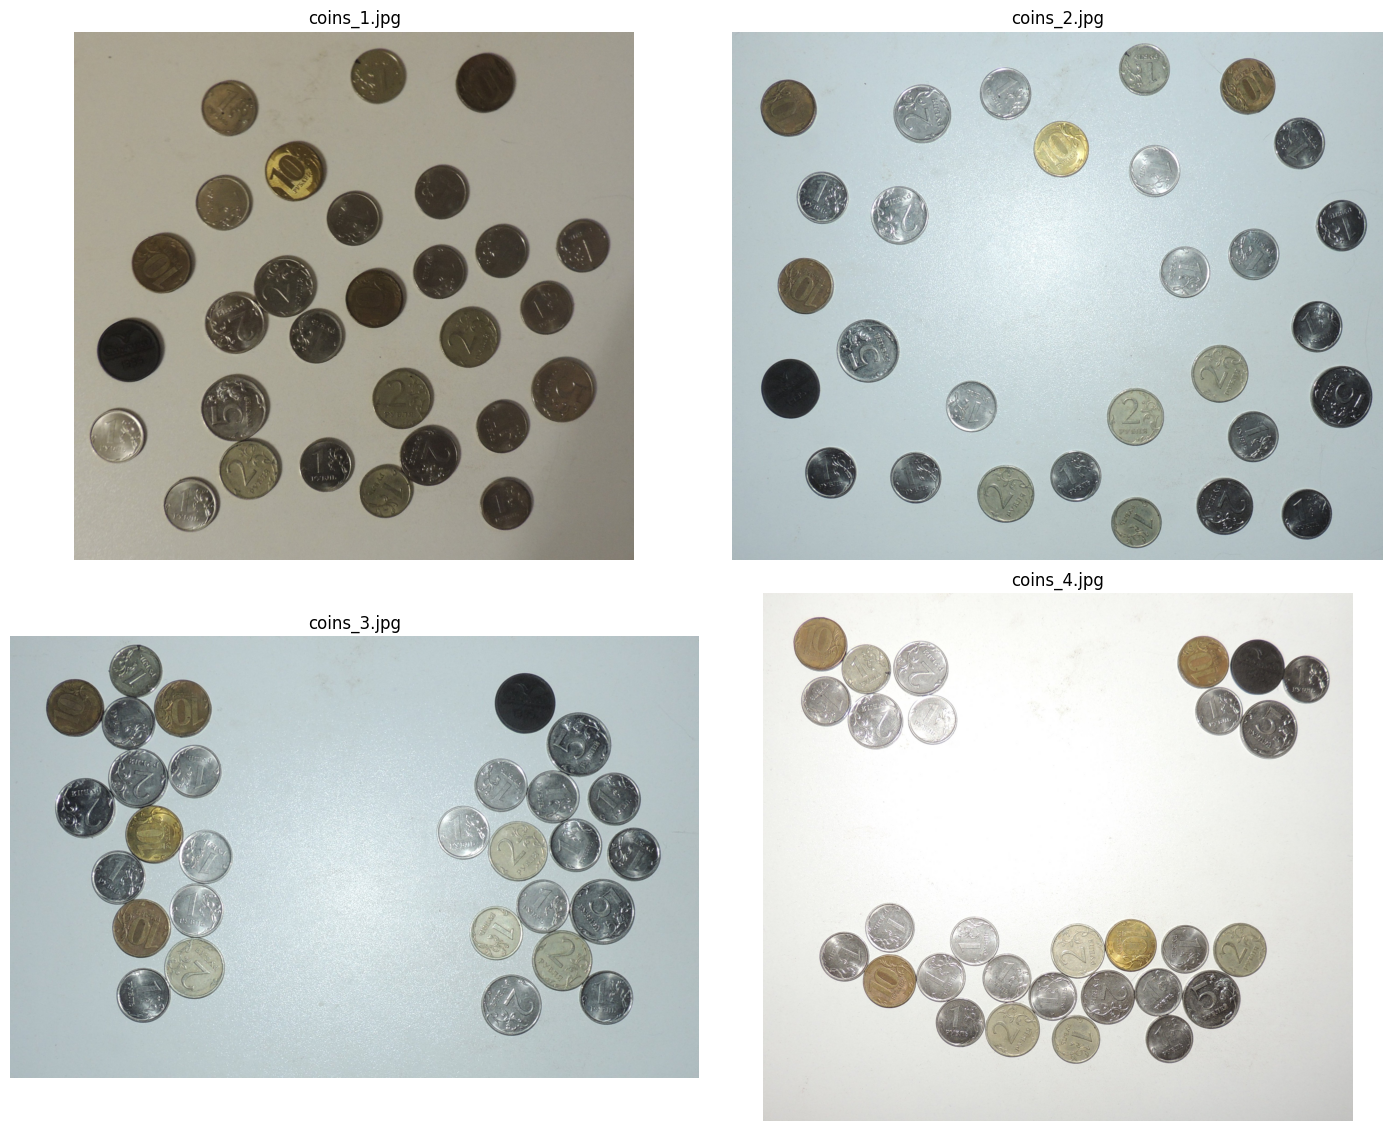

In [2]:
def load_image(path):
    """Загружает цветное изображение из файла."""
    if not isinstance(path, str):
        raise TypeError("Путь к изображению должен быть строкой.")
    if not os.path.exists(path):
        raise FileNotFoundError(f"Файл не найден: {path}")
    img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Не удалось декодировать изображение: {path}")
    return img


def capture_from_camera(camera_index=0):
    """Делает один снимок с камеры (только при локальном запуске)."""
    cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        raise RuntimeError("Камера недоступна.")
    ok, frame = cap.read()
    cap.release()
    if not ok:
        raise RuntimeError("Не удалось получить кадр с камеры.")
    return frame


def resize_to_width(img, width):
    """Масштабирует изображение к заданной ширине с сохранением пропорций."""
    h, w = img.shape[:2]
    scale = width / w
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_CUBIC
    return cv2.resize(img, (width, round(h * scale)), interpolation=interp)


def show(images, titles, cols=None, size=6):
    """Вывод нескольких изображений (BGR или оттенки серого) через matplotlib."""
    n = len(images)
    cols = cols or n
    rows = (n + cols - 1) // cols
    fig, ax = plt.subplots(rows, cols, figsize=(size * cols, size * 0.8 * rows), squeeze=False,
                           constrained_layout=True)
    for a in ax.ravel():
        a.axis("off")
    for a, img, title in zip(ax.ravel(), images, titles):
        a.imshow(img, cmap="gray") if img.ndim == 2 else a.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        a.set_title(title)
    plt.show()


PHOTOS = [f"coins_{i}.jpg" for i in range(1, 5)]
show([load_image(p) for p in PHOTOS], PHOTOS, cols=2, size=7)

### **3. Предобработка изображения**

Оттенки серого → размытие Гаусса (подавляет шум и рельеф чеканки) → оператор Кэнни (границы).

> `cv2.HoughCircles` с методом `HOUGH_GRADIENT` сам вычисляет границы Кэнни (верхний порог — `param1`, нижний — `param1 / 2`) и использует направление градиента. Поэтому на вход ему подаётся **размытое изображение в оттенках серого**, а результат `cv2.Canny` с теми же порогами выводится для визуального контроля.

In [3]:
def preprocess(img, params):
    """Возвращает (оттенки серого, размытое изображение, границы Кэнни)."""
    k = int(params["blur_ksize"])
    if k < 1 or k % 2 == 0:
        raise ValueError("blur_ksize должен быть положительным нечётным числом.")
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (k, k), 0)
    edges = cv2.Canny(blurred, params["canny_low"], params["canny_high"])
    return gray, blurred, edges

### **4. Обнаружение кругов (монет) и измерение радиуса**

Преобразование Хафа даёт центр и радиус каждой монеты. Различия в размере монет небольшие (1 руб. — 20,5 мм, 2 руб. — 23 мм, 5 руб. — 25 мм; 2 и 5 рублей отличаются всего на 8 %), а радиус Хафа иногда «цепляется» за внутренний кант монеты. Поэтому радиус **уточняется по градиенту**: из центра выпускаются 72 луча, на каждом находится внешний сильный перепад яркости (край монеты), и берётся медиана по всем лучам. Медиана устойчива к касающимся монетам и бликам.

In [4]:
def detect_circles(blurred, params):
    """Находит окружности преобразованием Хафа. Возвращает массив (N, 3): x, y, r."""
    circles = cv2.HoughCircles(blurred, cv2.HOUGH_GRADIENT, dp=params["dp"], minDist=params["min_dist"],
                               param1=params["canny_high"], param2=params["param2"],
                               minRadius=int(params["min_radius"]), maxRadius=int(params["max_radius"]))
    if circles is None:
        return np.empty((0, 3), dtype=np.float32)
    return circles[0]


def gradient_magnitude(gray):
    """Модуль градиента яркости (оператор Собеля) — для уточнения радиуса."""
    g = cv2.GaussianBlur(gray, (5, 5), 0).astype(np.float32)
    return cv2.magnitude(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))


def measure_radius(grad, x, y, r, n_rays=72, lo=0.85, hi=1.2):
    """Уточнённый радиус: медиана расстояний до внешнего края монеты по n_rays лучам."""
    h, w = grad.shape
    radii = np.arange(lo * r, hi * r, 0.5)
    estimates = []
    for angle in np.linspace(0, 2 * np.pi, n_rays, endpoint=False):
        xs = (x + radii * np.cos(angle)).astype(int)
        ys = (y + radii * np.sin(angle)).astype(int)
        inside = (xs >= 0) & (xs < w) & (ys >= 0) & (ys < h)
        if inside.sum() < 0.8 * len(radii):          # луч выходит за пределы снимка
            continue
        profile = grad[ys[inside], xs[inside]]
        strong = np.flatnonzero(profile >= 0.5 * profile.max())
        estimates.append(radii[inside][strong[-1]])  # самый внешний сильный перепад
    return float(np.median(estimates)) if estimates else float(r)

### **5. Классификация монет и подсчёт суммы**

**Цвет.** Монеты 1, 2 и 5 рублей — «серебристые», 10 рублей — жёлтые (латунь). Чтобы цвет не зависел от освещения, сначала выравнивается баланс белого по фону (фон приводится к нейтрально-серому), затем в центральной части монеты вычисляются медианные тон `H` и насыщенность `S` в пространстве HSV. Жёлтая монета (высокая `S`, тон латуни) — 10 рублей. Очень тёмная монета (яркость бликов намного ниже фона) — посторонняя и в сумму не входит.

**Размер.** Пороги по радиусу зависят от высоты съёмки: на наших снимках радиус монеты 1 рубль меняется от ~47 до ~60 px. Поэтому пороги заданы **в миллиметрах** (середины между диаметрами соседних номиналов: 21,75 и 24 мм), а масштаб снимка (px/мм) находится автоматически: подбирается такое значение, при котором радиусы всех монет лучше всего совпадают с реальными диаметрами (для жёлтых — 22 мм, для серебристых — ближайший из 20,5 / 23 / 25 мм). При `auto_scale = False` используются пороги в пикселях `r_1_2`, `r_2_5`.

In [5]:
def white_balance(img, circles):
    """Баланс белого по фону: каналы масштабируются так, чтобы фон стал нейтрально-серым.
    Возвращает (скорректированное изображение, средняя яркость фона)."""
    mask = np.full(img.shape[:2], 255, np.uint8)
    for x, y, r in circles:
        cv2.circle(mask, (int(x), int(y)), int(r * 1.3), 0, -1)     # исключаем монеты
    background = np.array([np.median(img[:, :, c][mask > 0]) for c in range(3)])
    gain = background.mean() / np.maximum(background, 1)
    balanced = np.clip(img.astype(np.float32) * gain, 0, 255).astype(np.uint8)
    return balanced, float(background.mean())


def color_features(hsv, x, y, r, background_v):
    """Медианные тон и насыщенность центральной части монеты и яркость её бликов относительно фона."""
    mask = np.zeros(hsv.shape[:2], np.uint8)
    cv2.circle(mask, (int(x), int(y)), int(r * 0.8), 255, -1)
    h = float(np.median(hsv[:, :, 0][mask > 0]))
    s = float(np.median(hsv[:, :, 1][mask > 0]))
    v_rel = float(np.percentile(hsv[:, :, 2][mask > 0], 90)) / background_v
    return h, s, v_rel


def estimate_scale(coins):
    """Масштаб px/мм, при котором радиусы монет лучше всего совпадают с реальными диаметрами."""
    best_scale, best_cost = None, np.inf
    for scale in np.arange(2.0, 10.0, 0.002):
        cost = 0.0
        for c in coins:
            diameters = [COIN_DIAMETERS_MM[10]] if c["color"] == "yellow" else \
                        [COIN_DIAMETERS_MM[v] for v in (1, 2, 5)]
            rel_err = min(abs(c["r"] - scale * d / 2) for d in diameters) / c["r"]
            cost += min(rel_err, 0.05) ** 2          # ограничение влияния выбросов
        if cost < best_cost:
            best_scale, best_cost = scale, cost
    return best_scale


def classify(coin, params, scale=None):
    """Номинал монеты: 0 — посторонняя (не учитывается), иначе 1, 2, 5 или 10 рублей."""
    if coin["color"] == "dark":
        return 0
    if coin["color"] == "yellow":
        return 10
    if params["auto_scale"] and scale:
        d = 2 * coin["r"] / scale                     # диаметр в мм
        return 1 if d < params["d_1_2_mm"] else (2 if d < params["d_2_5_mm"] else 5)
    r = coin["r"]
    return 1 if r < params["r_1_2"] else (2 if r < params["r_2_5"] else 5)


COIN_COLORS = {0: (128, 128, 128), 1: (255, 140, 0), 2: (0, 200, 0), 5: (0, 0, 255), 10: (0, 215, 255)}


def draw_result(img, coins, total):
    """Рисует окружности, номиналы и общую сумму на копии изображения."""
    out = img.copy()
    for c in coins:
        x, y, r, value = int(round(c["x"])), int(round(c["y"])), int(round(c["r"])), c["value"]
        color = COIN_COLORS[value]
        cv2.circle(out, (x, y), r, color, 3, cv2.LINE_AA)
        label = str(value) if value else "?"
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_COMPLEX, 1.1, 3)
        org = (x - tw // 2, y + th // 2)
        cv2.putText(out, label, org, cv2.FONT_HERSHEY_COMPLEX, 1.1, (0, 0, 0), 7, cv2.LINE_AA)    # обводка
        cv2.putText(out, label, org, cv2.FONT_HERSHEY_COMPLEX, 1.1, color, 3, cv2.LINE_AA)
    cv2.rectangle(out, (0, 0), (out.shape[1], 56), (0, 0, 0), -1)
    cv2.putText(out, f"Общая сумма: {total} руб.", (20, 40), cv2.FONT_HERSHEY_COMPLEX, 1.1,
                (255, 255, 255), 2, cv2.LINE_AA)
    return out

### **6. Основная функция**

`count_coins()` объединяет все этапы. При `visible=True` выводятся промежуточные результаты и итоговое изображение.

In [6]:
def count_coins(image, params=PARAMS, visible=True, show_steps=True):
    """Находит монеты на изображении и считает их сумму.

    image — цветное изображение BGR (массив NumPy) или путь к файлу.
    Возвращает словарь: total (сумма), counts (количество по номиналам),
    coins (список монет), scale (px/мм), result (изображение с разметкой)."""
    # --- 1. Проверка и подготовка входных данных
    if isinstance(image, str):
        image = load_image(image)
    if not isinstance(image, np.ndarray) or image.ndim != 3 or image.shape[2] != 3:
        raise ValueError("Ожидается цветное изображение BGR (H x W x 3) или путь к файлу.")
    img = resize_to_width(image, params["work_width"])

    # --- 2. Предобработка
    gray, blurred, edges = preprocess(img, params)

    # --- 3. Обнаружение кругов
    circles = detect_circles(blurred, params)
    if len(circles) == 0:
        print("Монеты не обнаружены: попробуйте уменьшить param2 или изменить min_radius / max_radius.")
        if visible:
            show([gray, blurred, edges], ["Оттенки серого", "Размытие Гаусса", "Границы Кэнни"])
        return {"total": 0, "counts": {}, "coins": [], "scale": None, "result": img}

    # --- 4. Признаки каждой монеты: уточнённый радиус и цвет
    grad = gradient_magnitude(gray)
    balanced, background_v = white_balance(img, circles)
    hsv = cv2.cvtColor(balanced, cv2.COLOR_BGR2HSV)
    coins = []
    for x, y, r in circles:
        h, s, v_rel = color_features(hsv, x, y, r, background_v)
        color = "silver"
        if params["use_color"]:
            if s >= params["yellow_min_s"] and params["yellow_h"][0] <= h <= params["yellow_h"][1]:
                color = "yellow"
            elif v_rel < params["dark_max_v"]:
                color = "dark"
        coins.append({"x": float(x), "y": float(y), "r_hough": float(r),
                      "r": measure_radius(grad, x, y, r), "h": h, "s": s, "v_rel": v_rel, "color": color})

    # --- 5. Масштаб и классификация
    known = [c for c in coins if c["color"] != "dark"]
    scale = estimate_scale(known) if params["auto_scale"] and known else None
    for c in coins:
        c["value"] = classify(c, params, scale)
        c["d_mm"] = 2 * c["r"] / scale if scale else None

    # --- 6. Подсчёт суммы
    total = sum(c["value"] for c in coins)
    counts = {v: sum(c["value"] == v for c in coins) for v in (1, 2, 5, 10, 0)}
    result = draw_result(img, coins, total)

    # --- 7. Вывод
    if visible:
        if show_steps:
            hough_vis = img.copy()
            for c in coins:
                cv2.circle(hough_vis, (int(c["x"]), int(c["y"])), int(c["r_hough"]), (0, 255, 0), 2, cv2.LINE_AA)
                cv2.circle(hough_vis, (int(c["x"]), int(c["y"])), 3, (0, 0, 255), -1)
            show([gray, blurred, edges, hough_vis, balanced],
                 ["1. Оттенки серого", f"2. Размытие Гаусса {params['blur_ksize']}x{params['blur_ksize']}",
                  f"3. Границы Кэнни ({params['canny_low']}, {params['canny_high']})",
                  f"4. Преобразование Хафа: {len(coins)} кругов", "5. Баланс белого (для оценки цвета)"],
                 cols=3, size=6)
        show([result], ["Результат"], size=11)
        scale_text = f", масштаб {scale:.2f} px/мм" if scale else ""
        print(f"Найдено монет: {len(coins)}{scale_text}")
        print(f"  1 руб.: {counts[1]}, 2 руб.: {counts[2]}, 5 руб.: {counts[5]}, 10 руб.: {counts[10]}, "
              f"посторонних: {counts[0]}")
        print(f"Общая сумма: {total} рублей")
    return {"total": total, "counts": counts, "coins": coins, "scale": scale, "result": result}

### **7. Настройка параметров через трекбары**

Функция открывает окно OpenCV с ползунками и пересчитывает результат при каждом изменении. Окна `cv2.imshow` работают только при **локальном** запуске (в Google Colab их нет), поэтому вызов закомментирован. Закрыть окно — клавиша `Esc`; выбранные значения сохраняются в `PARAMS`.

In [7]:
def tune_with_trackbars(image, params=PARAMS):
    """Интерактивный подбор параметров ползунками (только локальный запуск)."""
    img = resize_to_width(image, params["work_width"])
    win = "Coins: tuning (Esc - exit)"
    cv2.namedWindow(win, cv2.WINDOW_NORMAL)
    # Трекбары работают только с целыми числами
    sliders = {"blur_ksize": 31, "canny_high": 300, "param2": 150, "min_dist": 300,
               "min_radius": 200, "max_radius": 300, "yellow_min_s": 255}
    for name, maximum in sliders.items():
        cv2.createTrackbar(name, win, int(params[name]), maximum, lambda v: None)
    cv2.createTrackbar("dp x10", win, int(params["dp"] * 10), 30, lambda v: None)
    cv2.createTrackbar("auto_scale", win, int(params["auto_scale"]), 1, lambda v: None)

    while True:
        for name in sliders:
            params[name] = cv2.getTrackbarPos(name, win)
        params["blur_ksize"] = max(1, params["blur_ksize"] | 1)     # только нечётные значения
        params["canny_low"] = params["canny_high"] // 2
        params["param2"] = max(1, params["param2"])
        params["min_dist"] = max(1, params["min_dist"])
        params["dp"] = max(10, cv2.getTrackbarPos("dp x10", win)) / 10
        params["auto_scale"] = bool(cv2.getTrackbarPos("auto_scale", win))
        result = count_coins(img, params, visible=False)["result"]
        cv2.imshow(win, result)
        if cv2.waitKey(100) & 0xFF == 27:                           # Esc
            break
    cv2.destroyAllWindows()
    print("Подобранные параметры:", params)
    return params


# tune_with_trackbars(load_image("coins_2.jpg"))   # раскомментировать при локальном запуске

### **8. Эксперимент: подбор порогов по радиусу**

**Шаг 1.** Пороги в пикселях подобраны по снимку `coins_2.jpg`: радиусы монет 1 руб. — 47–49 px, 2 руб. — 54–55 px, 5 руб. — ~58 px, отсюда `r_1_2 = 51.5`, `r_2_5 = 56.5`. Проверим эти пороги на всех снимках (`auto_scale = False`).

In [8]:
EXPECTED = {1: 16, 2: 6, 5: 2, 10: 4, 0: 1}     # состав монет на каждом снимке
EXPECTED_TOTAL = 78


def print_report(title, params):
    print(title)
    print(f"{'Снимок':<12}{'1 р.':>6}{'2 р.':>6}{'5 р.':>6}{'10 р.':>7}{'посторон.':>11}{'Сумма':>8}{'Ошибка':>8}")
    print(f"{'ожидается':<12}{EXPECTED[1]:>6}{EXPECTED[2]:>6}{EXPECTED[5]:>6}{EXPECTED[10]:>7}{EXPECTED[0]:>11}{EXPECTED_TOTAL:>8}")
    runs = {}
    for path in PHOTOS:
        res = count_coins(path, params, visible=False)
        k = res["counts"]
        print(f"{path:<12}{k[1]:>6}{k[2]:>6}{k[5]:>6}{k[10]:>7}{k[0]:>11}{res['total']:>8}{res['total'] - EXPECTED_TOTAL:>+8}")
        runs[path] = res
    return runs


fixed_params = dict(PARAMS, auto_scale=False)
runs_fixed = print_report("Фиксированные пороги в пикселях (auto_scale = False):", fixed_params)

Фиксированные пороги в пикселях (auto_scale = False):
Снимок        1 р.  2 р.  5 р.  10 р.  посторон.   Сумма  Ошибка
ожидается       16     6     2      4          1      78
coins_1.jpg      0     0    21      7          1     175     +97
coins_2.jpg     16     6     2      4          1      78      +0
coins_3.jpg     16     6     2      4          1      78      +0
coins_4.jpg      5    12     7      4          1     104     +26


C:\Users\Ilya\AppData\Local\Temp\ipykernel_12788\1054422652.py:10: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax[0].scatter(i + 1 + jitter, c["r"], color=color, marker=markers[c["value"]], s=45, edgecolor="k", lw=0.4)
C:\Users\Ilya\AppData\Local\Temp\ipykernel_12788\1054422652.py:12: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax[1].scatter(i + 1 + jitter, c["d_mm"], color=color, marker=markers[c["value"]], s=45, edgecolor="k", lw=0.4)


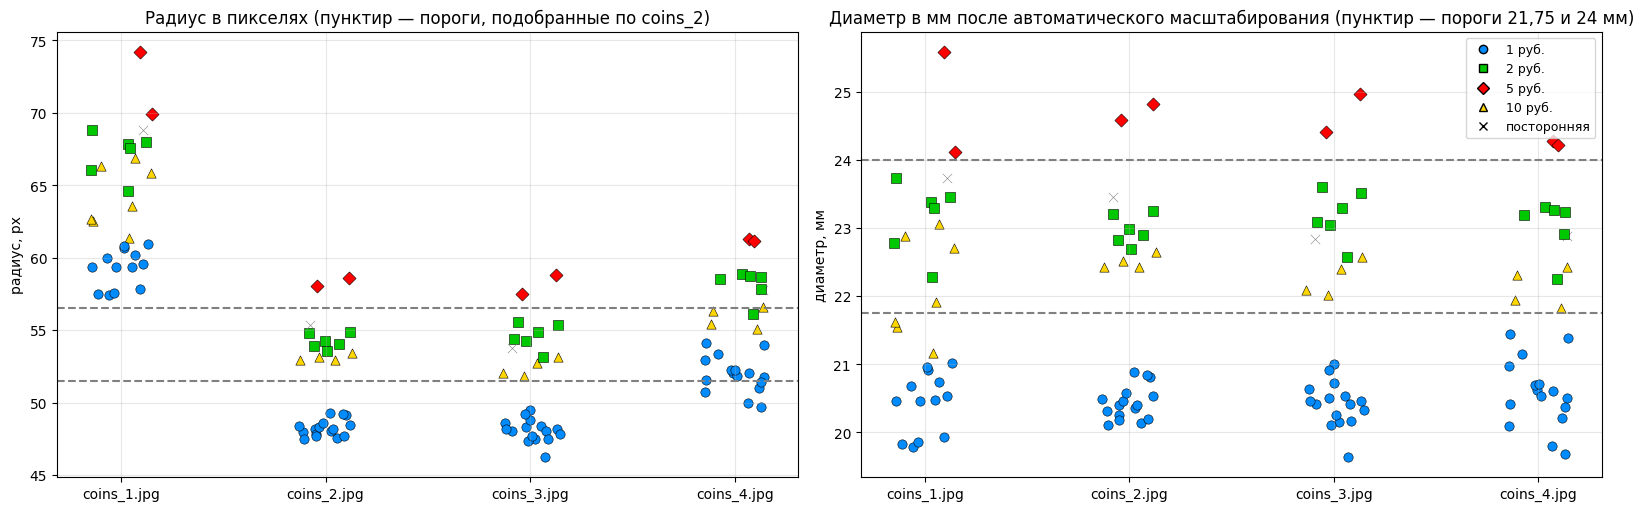

coins_1.jpg: масштаб 5.80 px/мм
coins_2.jpg: масштаб 4.72 px/мм
coins_3.jpg: масштаб 4.71 px/мм
coins_4.jpg: масштаб 5.05 px/мм


In [9]:
# Радиусы монет на каждом снимке: видно, что все значения смещаются в зависимости от высоты съёмки
fig, ax = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
markers = {1: "o", 2: "s", 5: "D", 10: "^", 0: "x"}
runs_auto = {p: count_coins(p, PARAMS, visible=False) for p in PHOTOS}
rng = np.random.default_rng(0)                    # небольшой горизонтальный разброс точек для наглядности
for i, path in enumerate(PHOTOS):
    for c in runs_auto[path]["coins"]:
        jitter = rng.uniform(-0.15, 0.15)
        color = np.array(COIN_COLORS[c["value"]][::-1]) / 255
        ax[0].scatter(i + 1 + jitter, c["r"], color=color, marker=markers[c["value"]], s=45, edgecolor="k", lw=0.4)
        if c["d_mm"]:
            ax[1].scatter(i + 1 + jitter, c["d_mm"], color=color, marker=markers[c["value"]], s=45, edgecolor="k", lw=0.4)
for thr in (PARAMS["r_1_2"], PARAMS["r_2_5"]):
    ax[0].axhline(thr, color="gray", ls="--")
for thr in (PARAMS["d_1_2_mm"], PARAMS["d_2_5_mm"]):
    ax[1].axhline(thr, color="gray", ls="--")
ax[0].set_title("Радиус в пикселях (пунктир — пороги, подобранные по coins_2)")
ax[0].set_ylabel("радиус, px")
ax[1].set_title("Диаметр в мм после автоматического масштабирования (пунктир — пороги 21,75 и 24 мм)")
ax[1].set_ylabel("диаметр, мм")
for a in ax:
    a.set_xticks(range(1, 5), PHOTOS)
    a.grid(alpha=0.3)
handles = [plt.Line2D([], [], marker=markers[v], ls="", color=np.array(COIN_COLORS[v][::-1]) / 255,
                      markeredgecolor="k", label=lbl)
           for v, lbl in ((1, "1 руб."), (2, "2 руб."), (5, "5 руб."), (10, "10 руб."), (0, "посторонняя"))]
ax[1].legend(handles=handles, loc="upper right", fontsize=9)
plt.show()

for path in PHOTOS:
    print(f"{path}: масштаб {runs_auto[path]['scale']:.2f} px/мм")

**Шаг 2.** На левом графике видно, что на снимке `coins_1.jpg` (камера ближе к монетам) все радиусы больше, и пороги, подобранные по одному снимку, на нём не работают; на `coins_4.jpg` они тоже смещены. Поэтому пороги переведены в миллиметры, а масштаб определяется для каждого снимка автоматически (правый график): диаметры монет каждого номинала собираются у своих реальных значений 20,5 / 23 / 25 мм, и общие пороги 21,75 и 24 мм их разделяют.

In [10]:
runs_auto = print_report("Пороги в миллиметрах + автоматический масштаб (auto_scale = True):", PARAMS)

Пороги в миллиметрах + автоматический масштаб (auto_scale = True):
Снимок        1 р.  2 р.  5 р.  10 р.  посторон.   Сумма  Ошибка
ожидается       16     6     2      4          1      78
coins_1.jpg     13     6     2      7          1     105     +27
coins_2.jpg     16     6     2      4          1      78      +0
coins_3.jpg     16     6     2      4          1      78      +0
coins_4.jpg     16     6     2      4          1      78      +0


### **9. Результаты на тестовых снимках**

Подробно, со всеми этапами обработки, — снимок `coins_2.jpg`:

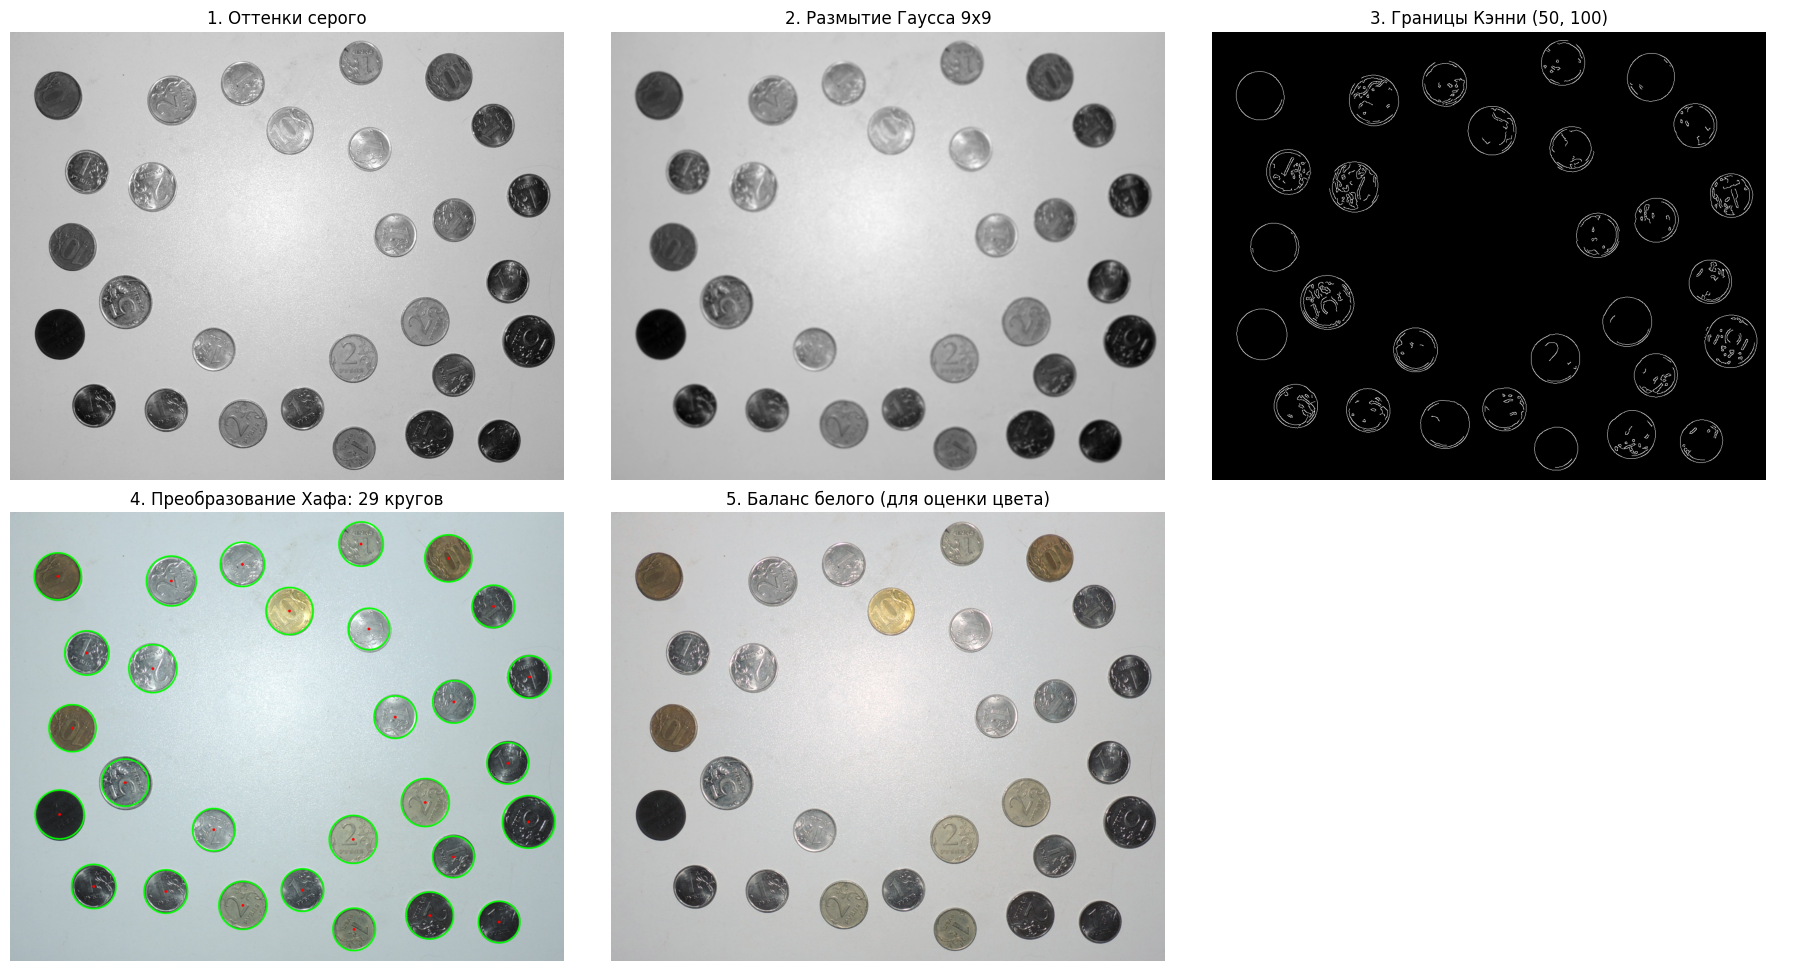

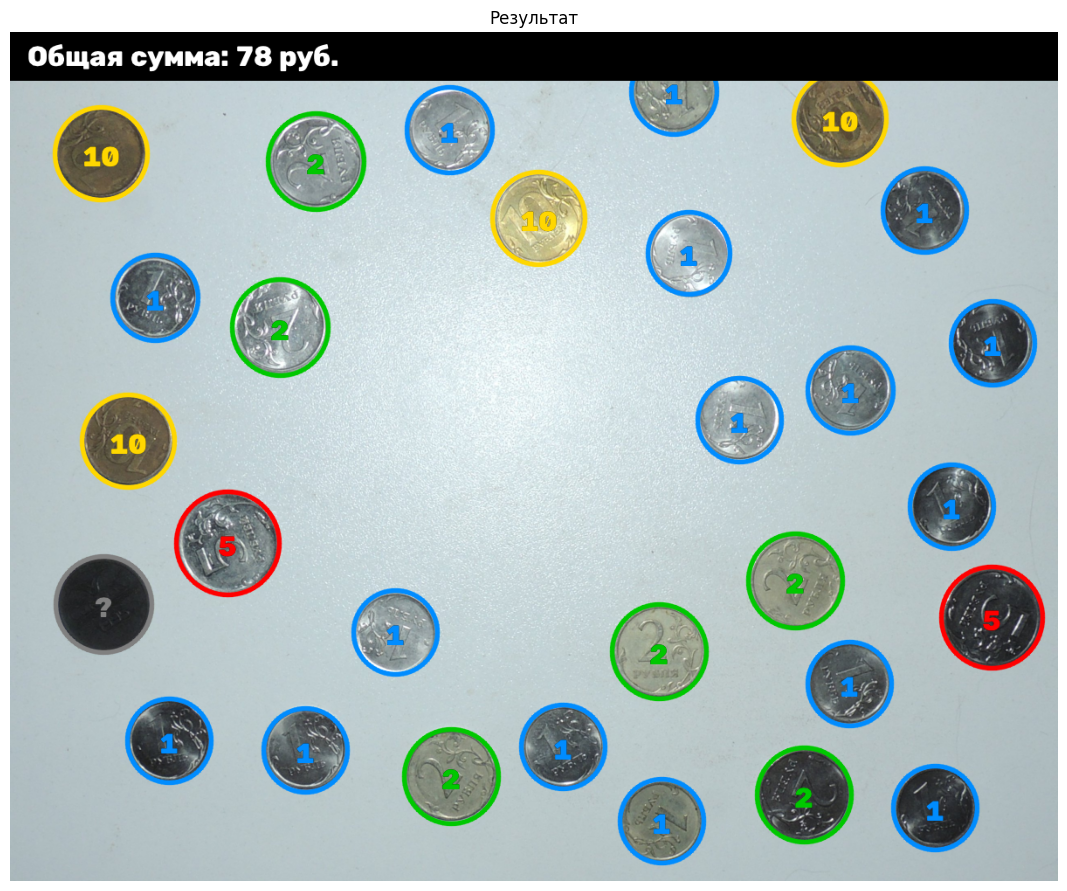

Найдено монет: 29, масштаб 4.72 px/мм
  1 руб.: 16, 2 руб.: 6, 5 руб.: 2, 10 руб.: 4, посторонних: 1
Общая сумма: 78 рублей


In [17]:
res = count_coins("coins_2.jpg", PARAMS, visible=True, show_steps=True)

Остальные снимки (касающиеся монеты — `coins_3.jpg`, `coins_4.jpg`; засвеченный центр — `coins_4.jpg`; тусклое тёплое освещение — `coins_1.jpg`):

===== coins_3.jpg =====


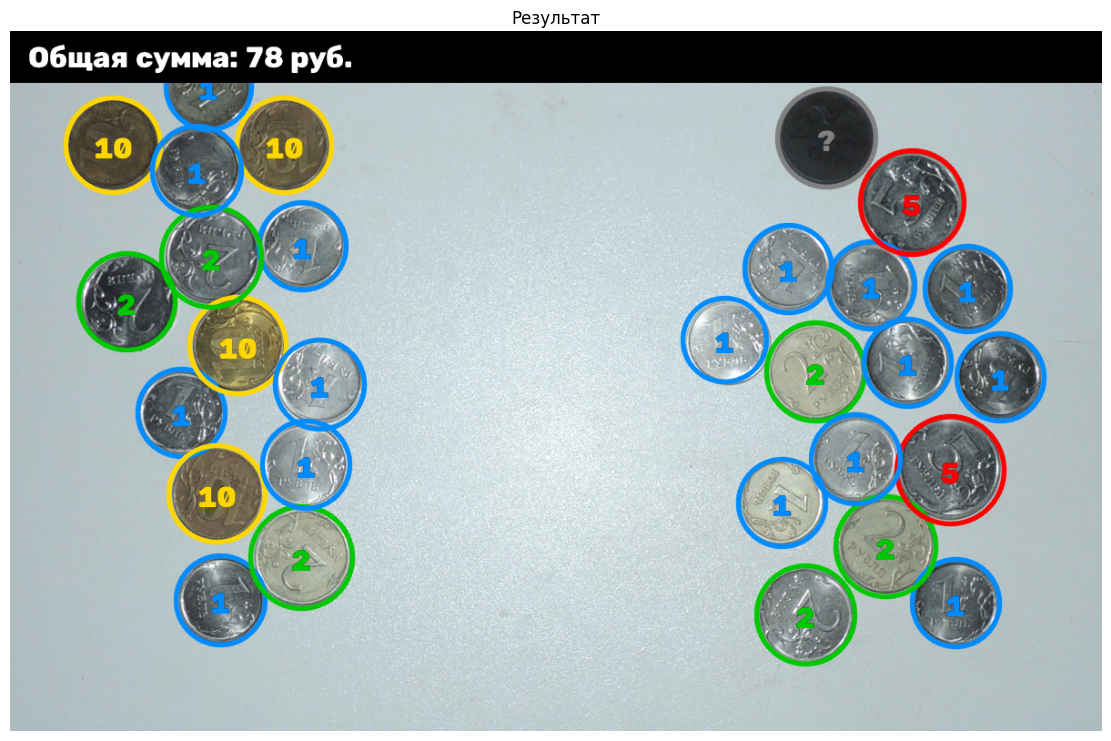

Найдено монет: 29, масштаб 4.71 px/мм
  1 руб.: 16, 2 руб.: 6, 5 руб.: 2, 10 руб.: 4, посторонних: 1
Общая сумма: 78 рублей
===== coins_4.jpg =====


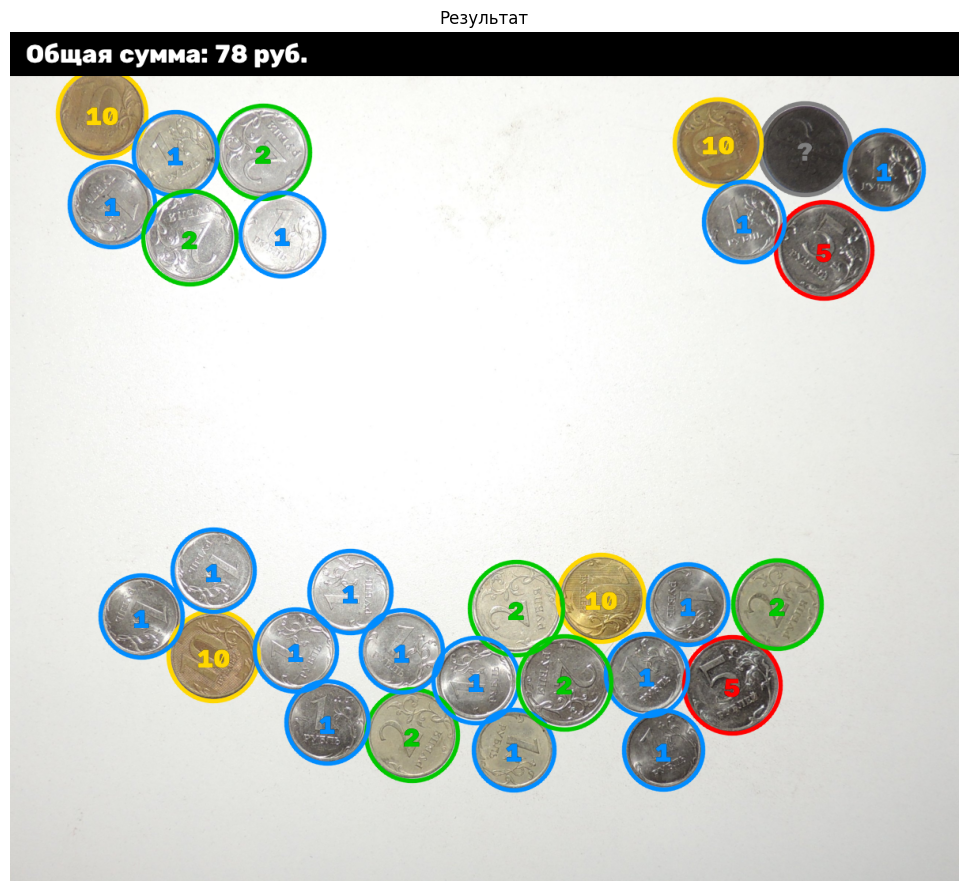

Найдено монет: 29, масштаб 5.05 px/мм
  1 руб.: 16, 2 руб.: 6, 5 руб.: 2, 10 руб.: 4, посторонних: 1
Общая сумма: 78 рублей
===== coins_1.jpg =====


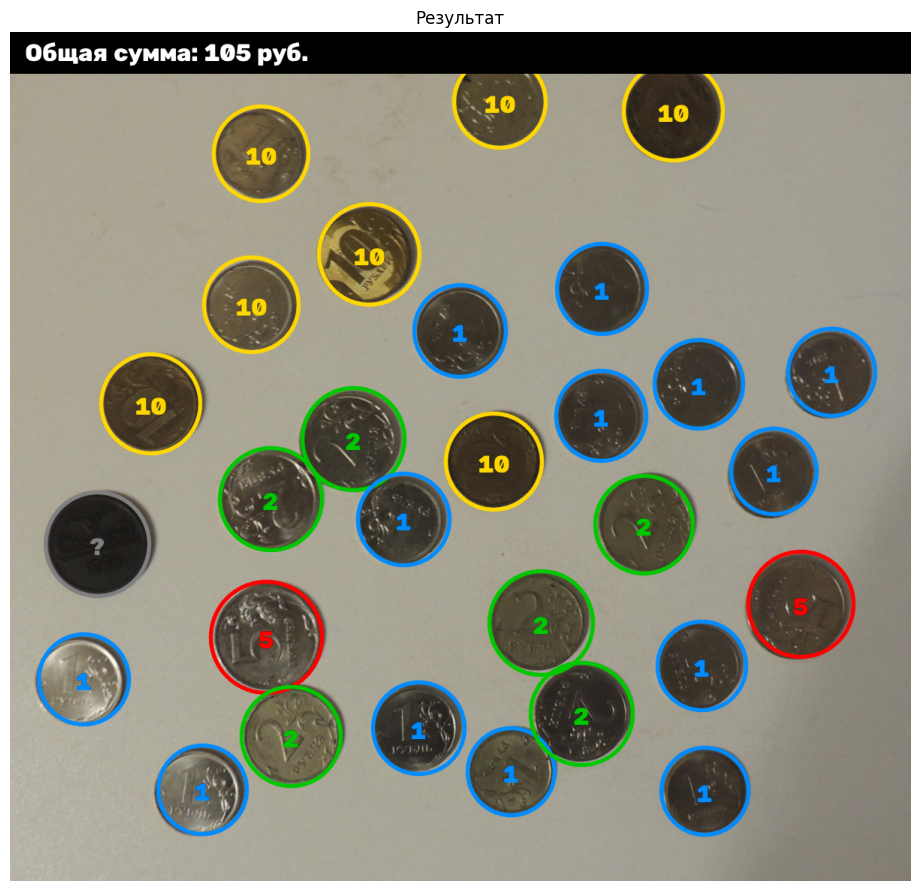

Найдено монет: 29, масштаб 5.80 px/мм
  1 руб.: 13, 2 руб.: 6, 5 руб.: 2, 10 руб.: 7, посторонних: 1
Общая сумма: 105 рублей


In [12]:
for path in ("coins_3.jpg", "coins_4.jpg", "coins_1.jpg"):
    print(f"===== {path} =====")
    count_coins(path, PARAMS, visible=True, show_steps=False)

     x     y     H     S   диаметр, мм
   321   364    20    75         21.56
   883   106    16    82         22.88
   652    94    21    84         21.17
   644   573    17    88         21.92
   334   163    19    89         21.62
   187   496    17    96         22.71
   478   297    20   125         23.06


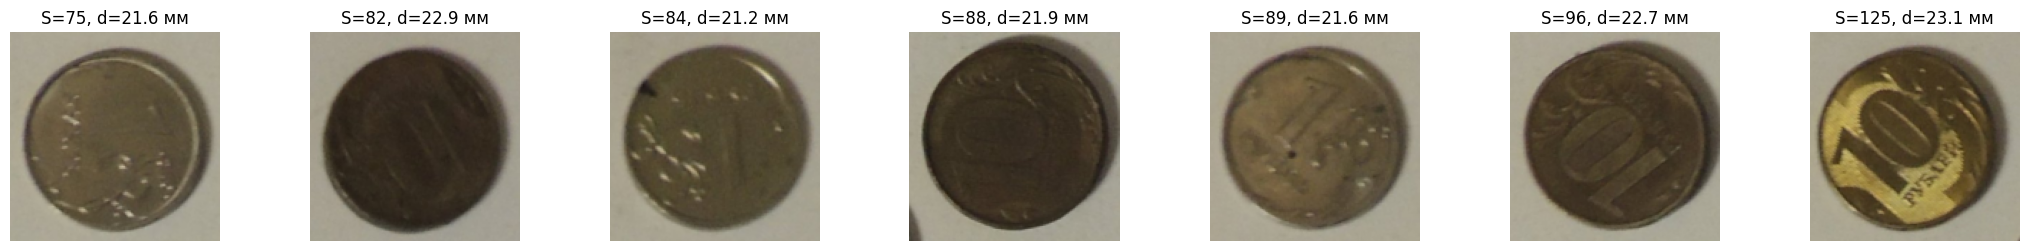

In [13]:
# Разбор ошибок на coins_1.jpg: монеты, распознанные как 10 руб. по цвету, и их признаки
res1 = count_coins("coins_1.jpg", PARAMS, visible=False)
yellow = [c for c in res1["coins"] if c["color"] == "yellow"]
print(f"{'x':>6}{'y':>6}{'H':>6}{'S':>6}{'диаметр, мм':>14}")
for c in sorted(yellow, key=lambda c: c["s"]):
    print(f"{c['x']:>6.0f}{c['y']:>6.0f}{c['h']:>6.0f}{c['s']:>6.0f}{c['d_mm']:>14.2f}")

img1 = resize_to_width(load_image("coins_1.jpg"), PARAMS["work_width"])
crops = [img1[int(c["y"] - c["r"] * 1.1):int(c["y"] + c["r"] * 1.1), int(c["x"] - c["r"] * 1.1):int(c["x"] + c["r"] * 1.1)]
         for c in sorted(yellow, key=lambda c: c["s"])]
show(crops, [f"S={c['s']:.0f}, d={c['d_mm']:.1f} мм" for c in sorted(yellow, key=lambda c: c["s"])], size=3)

### **10. Выводы**

**Что сделано.** Программа на OpenCV и NumPy принимает фотографию монет, выполняет предобработку (оттенки серого, размытие Гаусса, оператор Кэнни), находит монеты преобразованием Хафа (`cv2.HoughCircles`), определяет номинал каждой монеты, рисует окружности и подписи номиналов и выводит общую сумму на изображении и в консоли. Параметры задаются в словаре `PARAMS` и могут подбираться трекбарами при локальном запуске.

**Обнаружение.** На всех четырёх снимках найдены все 29 монет без ложных срабатываний, в том числе касающиеся друг друга монеты (`coins_3.jpg`, `coins_4.jpg`): `minDist = 60` px меньше диаметра монеты, поэтому соседние монеты не сливаются, а `param2 = 40` отсекает ложные окружности на фоне.

**Определение номинала по радиусу.**
- Радиус Хафа иногда приходится на внутренний кант монеты; уточнение радиуса по градиенту вдоль 72 лучей даёт устойчивую оценку края.
- Пороги в пикселях, подобранные по одному снимку, не переносятся на другие: радиус монеты 1 рубль меняется от ~47 px до ~60 px в зависимости от высоты съёмки. На `coins_1.jpg` фиксированные пороги дают большую ошибку суммы.
- Пороги в миллиметрах (21,75 и 24 мм) с автоматическим определением масштаба работают при любой высоте съёмки: на всех четырёх снимках монеты 1, 2 и 5 рублей разделены по размеру без ошибок (масштаб от 4,71 до 5,80 px/мм). Запас у порога 2 / 5 рублей небольшой: на `coins_1.jpg` одна монета 5 рублей измерена как 24,1 мм — точность измерения около ±0,5 мм, поэтому для надёжной работы монеты нужно снимать строго сверху и резко.

**Определение по цвету.** Монеты 10 рублей (22 мм) по размеру лежат между 1 и 2 рублями и по радиусу надёжно не отличаются, поэтому они распознаются по жёлтому цвету латуни, а тёмная посторонняя монета — по низкой яркости бликов. На снимках `coins_2.jpg`, `coins_3.jpg` и `coins_4.jpg` (ровный холодный свет) **все 29 монет определены правильно, сумма 78 рублей**.

**Ограничения.** На `coins_1.jpg` (тусклое тёплое освещение) три старые потемневшие монеты 1 рубль по цвету неотличимы от латунных 10 рублей (насыщенность 75–89 против 82–125 у 10 рублей) и засчитываются как 10 рублей: сумма 105 рублей вместо 78. По размеру эти монеты (21,2–21,6 мм) немного меньше десятирублёвых (21,9–23,1 мм), но разница всего около 0,3 мм (≈ 2 px) — меньше погрешности измерения, поэтому полагаться на неё нельзя. Цветовой признак требует ровного нейтрального освещения. Для улучшения можно: снимать при дневном свете или со вспышкой; учитывать одновременно цвет и размер (10 руб. — 22 мм, 1 руб. — 20,5 мм) при более точной калибровке масштаба, например по эталонному объекту известного размера; для перекрывающихся монет — применять водораздел (watershed).

**Вывод.** Преобразование Хафа надёжно находит монеты, а для определения номинала по радиусу важно учитывать масштаб снимка: пороги в пикселях подходят только для фиксированной высоты съёмки, пороги в миллиметрах с автоматическим масштабом — для любой.